# Bank Loan Management system

In [94]:
# Import libraries 
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [95]:
#load dataset
df = pd.read_csv("loan_approval_data_INR_raw.csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,1717217.5,133845.5,Salaried,51.0,Married,0.0,637.0,4.0,0.53,1872389.5,4404067.0,1603733.5,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,275990.0,258523.5,Salaried,46.0,Married,3.0,621.0,2.0,0.30,248970.0,4754748.0,3733295.5,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,713135.0,203229.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,1335946.0,666622.0,2696499.5,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,1347526.0,788694.5,Salaried,40.0,Married,2.0,579.0,3.0,0.31,921864.5,1046446.0,2684533.5,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,1281906.0,407519.5,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,905749.0,3631198.5,1229506.5,72.0,Car,NaN,Graduate,Male,Private,Yes


In [96]:
print("Dataset Shape:", df.shape)
df.info()

Dataset Shape: (1000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-nu

In [97]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object"]).columns

# Identify numerical columns
numerical_cols = df.select_dtypes(include=["number"]).columns

# Display categorical columns
print("Categorical Columns:")
print(list(categorical_cols))

# Display numerical columns
print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved']

Numerical Columns:
['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term']


In [98]:
# Check missing values in input features
print("Missing Values in Features:" , df.isnull().sum())

# Check total missing values in input features
print("\nTotal Missing Values in X:", df.isnull().sum().sum())

Missing Values in Features: Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

Total Missing Values in X: 1000


In [99]:
#number of duplicate
duplicate_count = df.duplicated().sum()
print("Number of Duplicate Rows:", duplicate_count)
duplicate_rows = df[df.duplicated()]
print("\nDuplicate Rows:",duplicate_rows)


Number of Duplicate Rows: 0

Duplicate Rows: Empty DataFrame
Columns: [Applicant_ID, Applicant_Income, Coapplicant_Income, Employment_Status, Age, Marital_Status, Dependents, Credit_Score, Existing_Loans, DTI_Ratio, Savings, Collateral_Value, Loan_Amount, Loan_Term, Loan_Purpose, Property_Area, Education_Level, Gender, Employer_Category, Loan_Approved]
Index: []


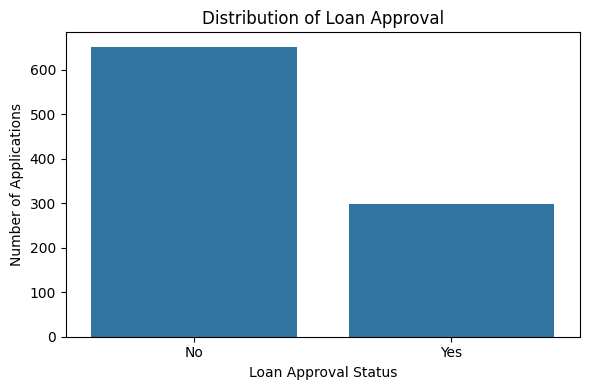

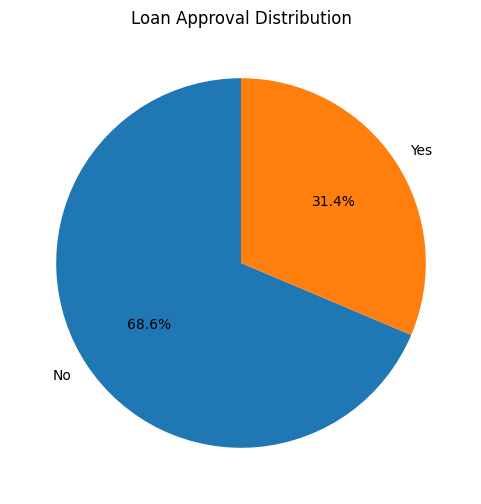

In [100]:
approval_counts = df["Loan_Approved"].value_counts()
# Plot the loan approval distribution using a bar graph
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Approved", order=approval_counts.index)
plt.title("Distribution of Loan Approval")
plt.xlabel("Loan Approval Status")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

# Plot the loan approval distribution using a pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    approval_counts,
    labels=approval_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Loan Approval Distribution")
plt.show()

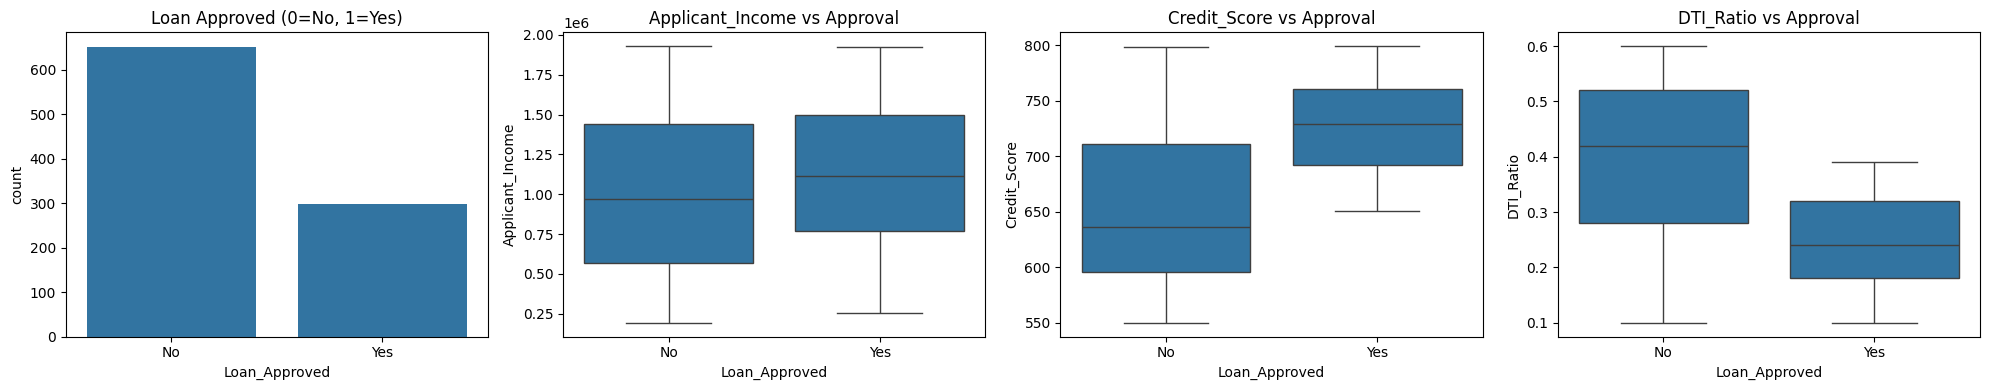

In [101]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

sns.countplot(x="Loan_Approved", data=df, ax=axes[0])
axes[0].set_title("Loan Approved (0=No, 1=Yes)")

for ax, col in zip(axes[1:], ["Applicant_Income", "Credit_Score", "DTI_Ratio"]):
    sns.boxplot(x="Loan_Approved", y=col, data=df, ax=ax)
    ax.set_title(f"{col} vs Approval")

plt.tight_layout()
plt.show()

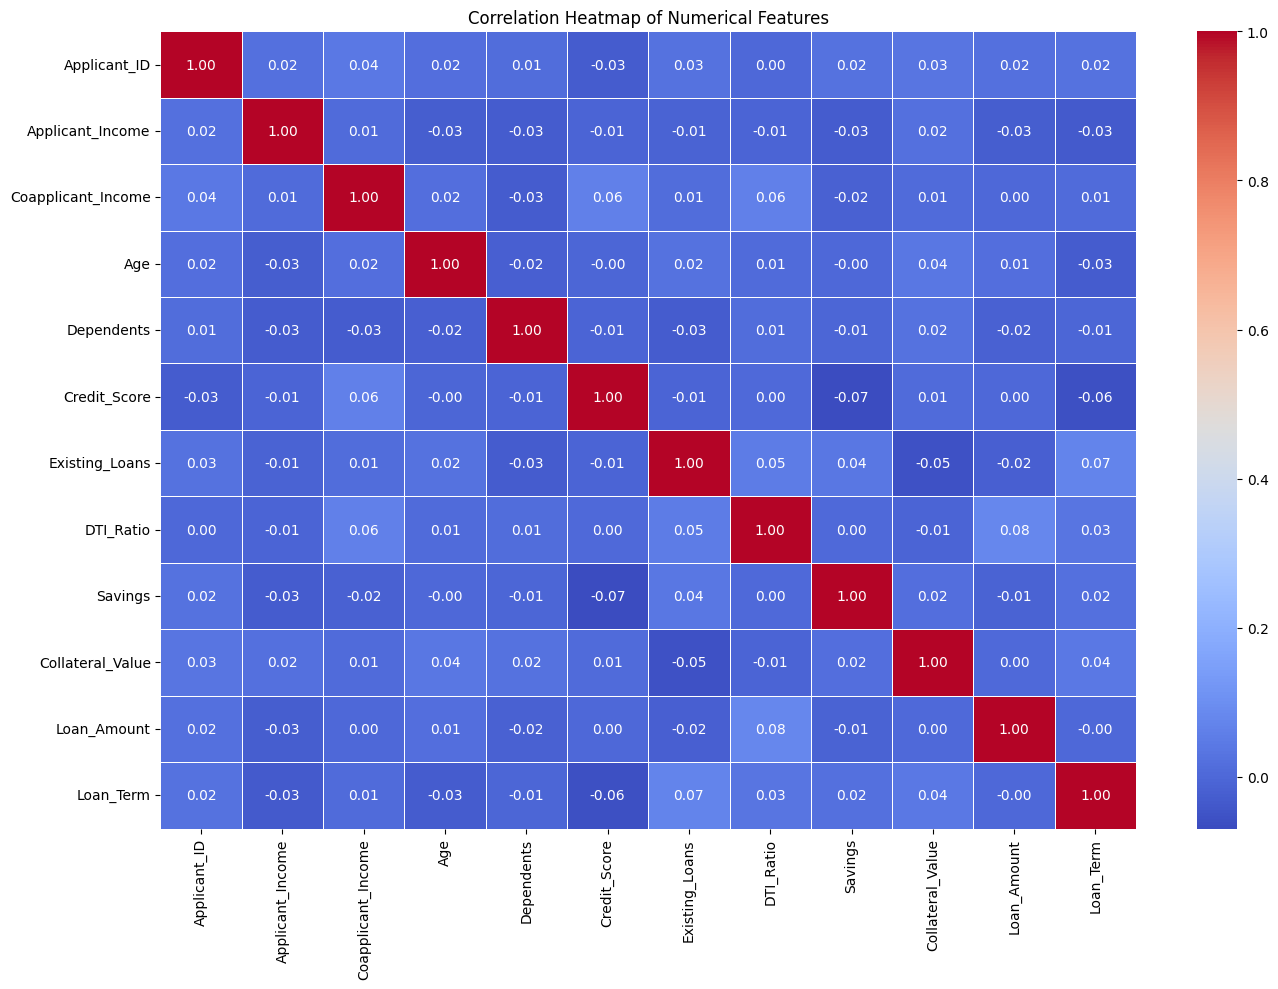

In [102]:
#correlation matrix
correlation_matrix = df[numerical_cols].corr()

# heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

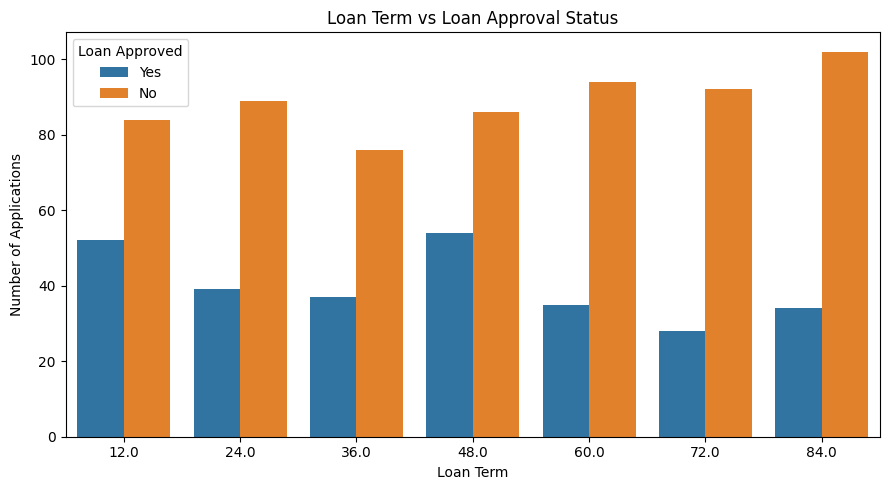

In [103]:
# Create a count plot comparing loan terms by approval status
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Loan_Term",
    hue="Loan_Approved"
)

plt.title("Loan Term vs Loan Approval Status")
plt.xlabel("Loan Term")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

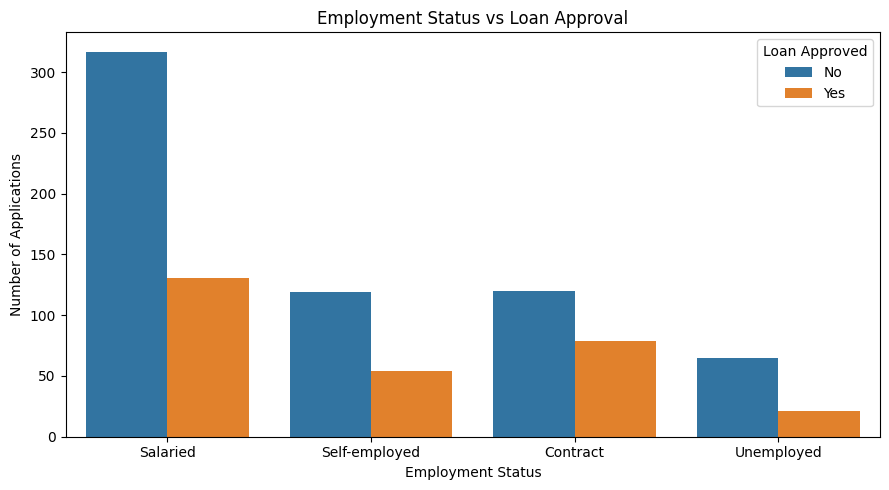

In [104]:
# Create a count plot comparing employment status and loan approval
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Employment_Status",
    hue="Loan_Approved"
)

plt.title("Employment Status vs Loan Approval")
plt.xlabel("Employment Status")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

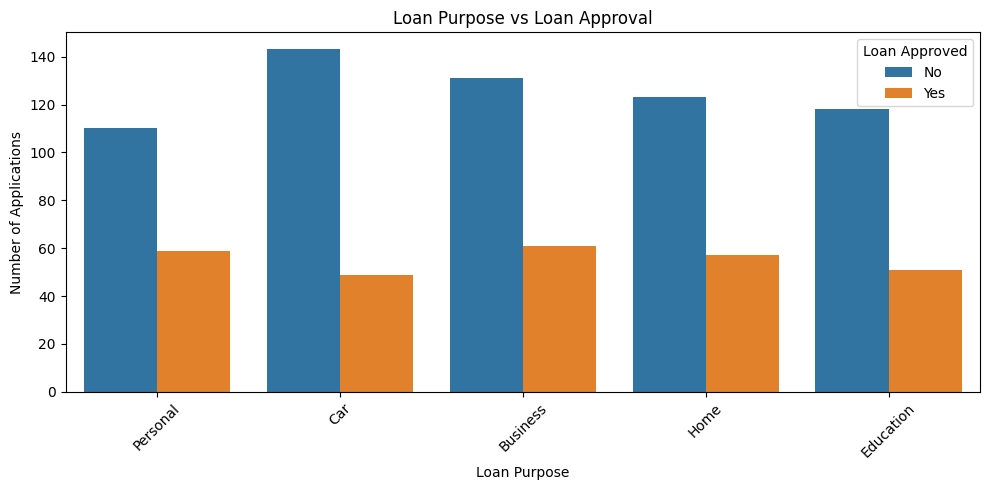

In [105]:
# Create a count plot comparing loan purpose and loan approval
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Loan_Purpose",
    hue="Loan_Approved"
)

plt.title("Loan Purpose vs Loan Approval")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

In [106]:
# Remove Applicant_ID because it is only an identifier
df = df.drop(columns=["Applicant_ID"], errors="ignore")

# Separate input features and target variable
X = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"]

# Display the feature and target information
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (1000, 18)
Target Shape: (1000,)

Input Features:
['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age', 'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']

Target Distribution:
Loan_Approved
No     652
Yes    298
Name: count, dtype: int64


In [107]:
# Check missing values in X and y
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

# Check rows with missing target values
print("\nRows with missing target:")
print(df[df["Loan_Approved"].isnull()])

Missing values in X: 900
Missing values in y: 50

Rows with missing target:
     Applicant_Income  Coapplicant_Income Employment_Status   Age  \
15           705511.5            125546.5          Salaried  42.0   
26          1921508.0            559314.0          Contract  28.0   
100          859815.0            671640.0     Self-employed  23.0   
122          543005.5            776246.0     Self-employed  30.0   
191         1081572.0            112422.5          Salaried  43.0   
195          390728.5             13992.5          Salaried  47.0   
263          211335.0            510967.5          Contract  49.0   
290         1825876.5            251286.0     Self-employed  23.0   
293         1034094.0            360717.0     Self-employed  38.0   
310               NaN             28371.0          Salaried  39.0   
312               NaN            953613.0          Contract  25.0   
314          487421.5            199176.0          Contract  50.0   
324          623872.5      

In [108]:
# Remove rows where the target variable is missing
df = df.dropna(subset=["Loan_Approved"]).copy()

# Separate features and target again
X = df.drop(columns=["Loan_Approved", "Applicant_ID"], errors="ignore")
y = df["Loan_Approved"]

# Verify the result
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isnull().sum())

Feature shape: (950, 18)
Target shape: (950,)
Missing target values: 0


In [109]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (760, 18)
Testing Features: (190, 18)

Training Target: (760,)
Testing Target: (190,)


In [110]:
## featuring engineerng
# Create a copy of the training and testing datasets
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Create Total Income feature
X_train_fe["Total_Income"] = (
    X_train_fe["Applicant_Income"] +
    X_train_fe["Coapplicant_Income"]
)

X_test_fe["Total_Income"] = (
    X_test_fe["Applicant_Income"] +
    X_test_fe["Coapplicant_Income"]
)

# Create Loan-to-Income Ratio
X_train_fe["Loan_to_Income_Ratio"] = (
    X_train_fe["Loan_Amount"] /
    X_train_fe["Total_Income"].replace(0, np.nan)
)

X_test_fe["Loan_to_Income_Ratio"] = (
    X_test_fe["Loan_Amount"] /
    X_test_fe["Total_Income"].replace(0, np.nan)
)

# Display the new features
print("New Features Created:")
print("1. Total_Income")
print("2. Loan_to_Income_Ratio")

print("\nTraining Data Shape Before Feature Engineering:", X_train.shape)
print("Training Data Shape After Feature Engineering:", X_train_fe.shape)

print("\nSample of Engineered Features:")
print(
    X_train_fe[
        ["Applicant_Income", "Coapplicant_Income",
         "Total_Income", "Loan_Amount", "Loan_to_Income_Ratio"]
    ].head()
)

New Features Created:
1. Total_Income
2. Loan_to_Income_Ratio

Training Data Shape Before Feature Engineering: (760, 18)
Training Data Shape After Feature Engineering: (760, 20)

Sample of Engineered Features:
     Applicant_Income  Coapplicant_Income  Total_Income  Loan_Amount  \
443          722399.0            880755.5     1603154.5    3493107.0   
212          732628.0            791493.0     1524121.0    1274186.0   
365         1550658.5            304457.5     1855116.0    2800044.0   
783          700204.0            931611.0     1631815.0    3761666.5   
667         1712392.5                 NaN           NaN     833856.5   

     Loan_to_Income_Ratio  
443              2.178896  
212              0.836014  
365              1.509363  
783              2.305204  
667                   NaN  


In [111]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical features
numerical_features = X_train_fe.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train_fe.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Numerical preprocessing: Median Imputation + Standard Scaling
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: Most Frequent Imputation + One-Hot Encoding
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

print("\nNumerical preprocessing: Median Imputation + Standard Scaling")
print("Categorical preprocessing: Most-Frequent Imputation + One-Hot Encoding")
print("\nPreprocessing pipeline created successfully!")

Numerical Features: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Total_Income', 'Loan_to_Income_Ratio']
Categorical Features: ['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']

Numerical preprocessing: Median Imputation + Standard Scaling
Categorical preprocessing: Most-Frequent Imputation + One-Hot Encoding

Preprocessing pipeline created successfully!


In [112]:
# fit transform
X_train_processed = preprocessor.fit_transform(X_train_fe)
X_test_processed = preprocessor.transform(X_test_fe)


print("Training Shape After Feature Engineering:", X_train_fe.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)



Training Shape After Feature Engineering: (760, 20)
Processed Training Shape: (760, 36)

Original Testing Shape: (190, 18)
Processed Testing Shape: (190, 36)


In [113]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
lr_model.fit(X_train_processed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [114]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
y_pred_lr = lr_model.predict(X_test_processed)
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)

# Display results in a simple format
print("Logistic Regression Results")
print("----------------------------")
print(f"Accuracy  : {lr_accuracy * 100:.2f}%")
print(f"Precision : {lr_precision * 100:.2f}%")
print(f"Recall    : {lr_recall * 100:.2f}%")
print(f"F1-Score  : {lr_f1 * 100:.2f}%")

Logistic Regression Results
----------------------------
Accuracy  : 88.95%
Precision : 83.05%
Recall    : 81.67%
F1-Score  : 82.35%


In [115]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Predict loan approval on testing data
y_pred_dt = dt_model.predict(X_test_processed)

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)

# Display results
print("Decision Tree Results")
print("---------------------")
print(f"Accuracy  : {dt_accuracy * 100:.2f}%")
print(f"Precision : {dt_precision * 100:.2f}%")
print(f"Recall    : {dt_recall * 100:.2f}%")
print(f"F1-Score  : {dt_f1 * 100:.2f}%")

Decision Tree Results
---------------------
Accuracy  : 93.68%
Precision : 88.71%
Recall    : 91.67%
F1-Score  : 90.16%


In [116]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict loan approval on testing data
y_pred_rf = rf_model.predict(X_test_processed)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)

# Display results
print("Random Forest Results")
print("---------------------")
print(f"Accuracy  : {rf_accuracy * 100:.2f}%")
print(f"Precision : {rf_precision * 100:.2f}%")
print(f"Recall    : {rf_recall * 100:.2f}%")
print(f"F1-Score  : {rf_f1 * 100:.2f}%")

Random Forest Results
---------------------
Accuracy  : 94.21%
Precision : 91.53%
Recall    : 90.00%
F1-Score  : 90.76%


In [117]:
# Convert loan approval labels into numerical values
y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

# Check the encoded labels
print("Training Target Labels:")
print(y_train_xgb.value_counts())

print("\nTesting Target Labels:")
print(y_test_xgb.value_counts())

Training Target Labels:
Loan_Approved
0    522
1    238
Name: count, dtype: int64

Testing Target Labels:
Loan_Approved
0    130
1     60
Name: count, dtype: int64


In [118]:
# Import XGBoost Classifier
from xgboost import XGBClassifier

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

# Train the model using encoded target labels
xgb_model.fit(X_train_processed, y_train_xgb)

# Predict loan approval on testing data
y_pred_xgb = xgb_model.predict(X_test_processed)

# Convert predictions back to Yes and No
y_pred_xgb = pd.Series(y_pred_xgb).map({0: "No", 1: "Yes"})

# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)
xgb_recall = recall_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)
xgb_f1 = f1_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)

# Display results
print("XGBoost Results")
print("----------------")
print(f"Accuracy  : {xgb_accuracy * 100:.2f}%")
print(f"Precision : {xgb_precision * 100:.2f}%")
print(f"Recall    : {xgb_recall * 100:.2f}%")
print(f"F1-Score  : {xgb_f1 * 100:.2f}%")

XGBoost Results
----------------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [119]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Store predictions from all four models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

# Create a dictionary to store model results
model_results = {}

# Calculate metrics for each model
for model_name, predictions in model_predictions.items():

    model_results[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100,
        "F1-Score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100
    }

# Display results
for model_name, metrics in model_results.items():
    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(f"Accuracy  : {metrics['Accuracy']:.2f}%")
    print(f"Precision : {metrics['Precision']:.2f}%")
    print(f"Recall    : {metrics['Recall']:.2f}%")
    print(f"F1-Score  : {metrics['F1-Score']:.2f}%")


Logistic Regression
-------------------
Accuracy  : 88.95%
Precision : 83.05%
Recall    : 81.67%
F1-Score  : 82.35%

Decision Tree
-------------
Accuracy  : 93.68%
Precision : 88.71%
Recall    : 91.67%
F1-Score  : 90.16%

Random Forest
-------------
Accuracy  : 94.21%
Precision : 91.53%
Recall    : 90.00%
F1-Score  : 90.76%

XGBoost
-------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [120]:
# Find the model with the highest F1-score
best_model_name = max(
    model_results,
    key=lambda model: model_results[model]["F1-Score"]
)

# Display the best model
print("Best Performing Model:", best_model_name)
print("-" * 40)

# Display its evaluation metrics
best_metrics = model_results[best_model_name]

print(f"Accuracy  : {best_metrics['Accuracy']:.2f}%")
print(f"Precision : {best_metrics['Precision']:.2f}%")
print(f"Recall    : {best_metrics['Recall']:.2f}%")
print(f"F1-Score  : {best_metrics['F1-Score']:.2f}%")

Best Performing Model: XGBoost
----------------------------------------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [121]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest
feature_importance = rf_model.feature_importances_

# Create a DataFrame of feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 most important features
print("Top 10 Important Features")
print("-------------------------")

for _, row in importance_df.head(10).iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f}")

Top 10 Important Features
-------------------------
num__Credit_Score: 0.3296
num__DTI_Ratio: 0.3258
num__Applicant_Income: 0.0543
num__Loan_to_Income_Ratio: 0.0413
num__Loan_Amount: 0.0406
num__Total_Income: 0.0345
num__Collateral_Value: 0.0271
num__Savings: 0.0213
num__Coapplicant_Income: 0.0191
num__Loan_Term: 0.0189


In [122]:
# Import joblib for saving machine learning models
import joblib

# Select the best model
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = models[best_model_name]

# Save the best model
joblib.dump(best_model, "best_loan_approval_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "loan_preprocessor.pkl")

# Display confirmation
print("Best Model:", best_model_name)
print("Model saved as: best_loan_approval_model.pkl")
print("Preprocessor saved as: loan_preprocessor.pkl")
print("\nModel and preprocessing pipeline saved successfully!")

Best Model: XGBoost
Model saved as: best_loan_approval_model.pkl
Preprocessor saved as: loan_preprocessor.pkl

Model and preprocessing pipeline saved successfully!


In [123]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())
print("preprocessor exists:", "preprocessor" in globals())
print("best_model exists:", "best_model" in globals())

X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True
preprocessor exists: True
best_model exists: True
